In [1]:
from os import chdir
from os.path import abspath
thepath = abspath("../base")
chdir(thepath)

In [2]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt

from os import makedirs, listdir
from os.path import exists, join, isdir, normpath
from stl import mesh
import iterative_section_minimiser as ism
from utils import find_neighbours_with_knn, return_source_target


A mapping to the conduits and their number.

In [3]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

A mapping of plotting keyword arguments.

In [4]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [5]:
skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct1_kwargs = p["ct1_kwargs"]
ct2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

In [6]:
# set up the conduit name and ID. 
ID = 6
CONDUIT_NAME = conduit_map[ID]

In [7]:
## import the mesh data. 
mesh_fp =  f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
data = mesh.Mesh.from_file(mesh_fp)

In [8]:
adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
if not exists(adj_triangles_fp):
    triangle_adjacency_matrix = find_neighbours_with_knn(data)
    np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
else: 
    triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)

In [9]:
with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
    process_p = yaml.safe_load(f)
    f.close()

In [ ]:
P1, nP1, P2, nP2 = return_source_target(mesh=data, 
                              adjacent_triangles=triangle_adjacency_matrix)

In [13]:
L = 45 # guess a max number of steps. 
# if the iterative section minimiser has already been run, then, don't run and
# simply call it up again. 
iterative_ct_fp = join("../temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_centreline.txt") 
sections_fp = f"../temp/{ID}_{CONDUIT_NAME}/iterative/sections2d"
sections3d_fp = f"../temp/{ID}_{CONDUIT_NAME}/iterative/sections3d"
iterative_vectors_fp = join("../temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_vectors.txt") 

keep_iterative = False

In [14]:
if keep_iterative == True:
    out_iterative = {}
    out_iterative["centreline"] = np.loadtxt(iterative_ct_fp)
    out_iterative["vertices"] = []
    out_iterative["normals"] = np.loadtxt(iterative_vectors_fp)

    for section2d_name in listdir(sections_fp):
        section2d_fp = normpath(join(sections_fp, section2d_name))
        out_iterative["vertices"].append(np.loadtxt(section2d_fp))

else:

    out_iterative = ism.iterative_pathfinder(mesh_data=data,
                                                 P_start=P1,
                                                 nP0=nP1.flatten(),
                                                 P_end=P2, L=L, ds = process_p["iterStepSize"], eps= 0.05)
    
    
    np.savetxt(iterative_ct_fp, out_iterative["centreline"])
    np.savetxt(iterative_vectors_fp, out_iterative["normals"])

    # save the normals
    #for section2d in sections:
    # save the 2d sections
    if not isdir(sections_fp):
        makedirs(sections_fp)
    for k, section in enumerate(out_iterative["vertices"]):
            np.savetxt(join(sections_fp, f"s2d_{k}.txt"), section)

 23%|██▎       | 20/87.0 [00:04<00:16,  4.11it/s]


empty intersection on too few triangles intersected.
ending on a none type


We can extract the iterative centreline from this process. 

In [15]:
iterative_ct = out_iterative["centreline"]

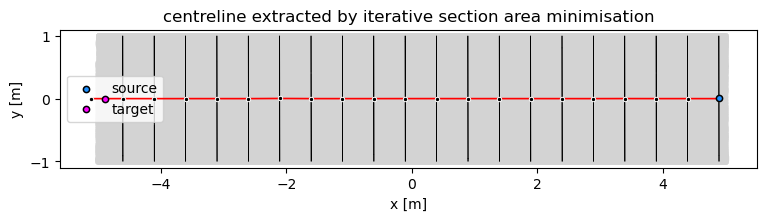

In [17]:
fig, ax = plt.subplots(figsize = (9, 5))
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.scatter(*out_iterative["centreline"][:, [0, 1]].T, 
           **node_kwargs)

ax.plot(*out_iterative["centreline"][:, [0, 1]].T, **ct_kwargs)

for vertex_set in out_iterative["vertices"]:
    ax.plot(*vertex_set[:, [0, 1]].T, color = "k", lw = 0.5)

## example for the ending criterion- needs to be within epsilon of plane and within d of the barycentre of section.
## if both are good, then stop!

ax.set_title("centreline extracted by iterative section area minimisation")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal")
ax.legend()

plt.savefig(f"../temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_extremities_iterative_pathfinder.png", dpi = 300)
plt.savefig(f"../temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_extremities_iterative_pathfinder.pdf")



We can also plot the number of iterations needed each time to reach the famous eps criterion for stopping. 
As well as the values of W and A which are computed at each step. We define the maximum number of iterations to be 20 and the stopping criterion to be 0.05 (5%).  

In [18]:
logs = out_iterative["logs"]

In [19]:
iteration_progress = []
steps = []
k = 0
j=0
for log in logs:
    
    steps.append(k)
    for iter in log:
        
    
    #print(np.linalg.norm(iter[3]))
        iteration_progress.append((np.linalg.norm(iter[3]), 
                                   iter[4], 
                                   np.linalg.norm(iter[3]) / iter[4], k, j))
        j+=1
    k+=1

In [20]:
iteration_progress = np.array(iteration_progress)

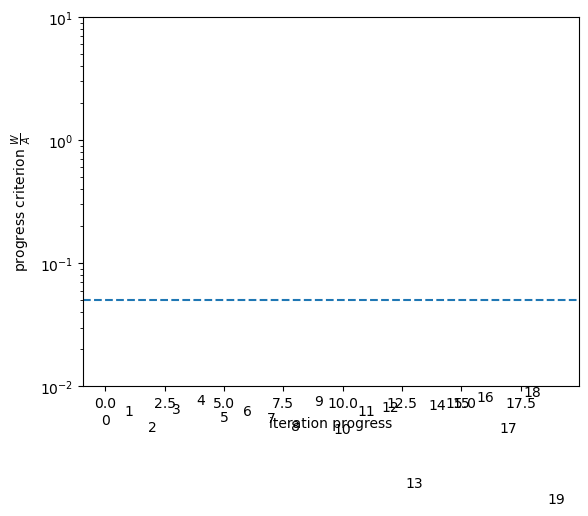

In [21]:
fig, ax= plt.subplots()
for k in np.unique(iteration_progress[:, 3]):
    thebool = iteration_progress[:, 3] == k
    ax.scatter(iteration_progress[thebool, 4],iteration_progress[thebool, 0], color = "k")
    ax.semilogy(iteration_progress[thebool, 4],iteration_progress[thebool, 0], color = "firebrick", zorder = -2)
    ax.text(iteration_progress[thebool, 4][0], iteration_progress[thebool, 0][0]*1.15, f"{int(k):d}", va = "bottom", ha="center")
ax.set_xlabel("iteration progress")
ax.set_ylabel("progress criterion $\\frac{W}{A}$")
ax.set_ylim(0.01, 10)
ax.axhline(0.05, color = "C0", ls ="--")